<div align="center">
  <img src="https://raw.githubusercontent.com/Udhay345/UWrites-AI-Powered-Personalized-Handwriting-Generation/main/assets/UWRITES-Pixel-Banner.png" width="100%" alt="UWrites Banner"/>
</div>

# UWrites: AI-Powered Personalized Handwriting Generation
### End-to-End Handwriting Preprocessing, Morphological Segmentation & Conditional DCGAN Synthesis

<p align="left">
  <a href="https://colab.research.google.com/github/Udhay345/UWrites-AI-Powered-Personalized-Handwriting-Generation/blob/main/notebooks/Uwrites.ipynb" target="_parent">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
  </a>
</p>

---

## Table of Contents
1. [Environment Setup & Dependencies](#1-environment-setup--dependencies)
2. [Data Acquisition & Storage Initialization](#2-data-acquisition--storage-initialization)
3. [Computer Vision Preprocessing & Segmentation Pipeline](#3-computer-vision-preprocessing--segmentation-pipeline)
4. [Batch Dataset Processing & Category Mapping](#4-batch-dataset-processing--category-mapping)
5. [Annotation & Transcription Ingestion](#5-annotation--transcription-ingestion)
6. [PyTorch Custom Dataset & Character Vocabulary Encoding](#6-pytorch-custom-dataset--character-vocabulary-encoding)
7. [Deep Generative Architecture: TextEncoder, Generator & Discriminator](#7-deep-generative-architecture-textencoder-generator--discriminator)
8. [Training Pipeline & Optimization Setup](#8-training-pipeline--optimization-setup)
9. [Adversarial Training Loop & Checkpointing](#9-adversarial-training-loop--checkpointing)
10. [Inference, Checkpoint Restoration & Visual Handwriting Synthesis](#10-inference-checkpoint-restoration--visual-handwriting-synthesis)
11. [Empirical Evaluation, Known Limitations & Technical Insights](#11-empirical-evaluation-known-limitations--technical-insights)

## 1. Environment Setup & Dependencies

In this section, we install and import the computer vision (`opencv`, `PIL`), deep learning (`torch`, `torchvision`), and numerical computing (`numpy`, `pandas`) libraries required for the pipeline.

In [ ]:
!pip install -q opencv-python-headless pillow numpy torch torchvision pandas openpyxl

import os
import cv2
import csv
import zipfile
import time
import glob
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

# Configure root directory (adaptable for Google Colab or local repo execution)
if os.path.exists('/content'):
    DATA_ROOT = '/content/handwriting-dataset'
else:
    # Running locally inside repository
    DATA_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

os.makedirs(DATA_ROOT, exist_ok=True)
print(f"Data root initialized at: {DATA_ROOT}")

## 2. Data Acquisition & Storage Initialization

When executing in Google Colab, raw scans can be uploaded via a zip archive (`raw_scans.zip` or `dataset.zip`). When running locally within the cloned repository, the pipeline directly accesses `../dataset`.

In [ ]:
# Check if running in Google Colab; otherwise check local dataset
try:
    from google.colab import files
    in_colab = True
except ImportError:
    in_colab = False

local_dataset_path = os.path.join(DATA_ROOT, 'dataset')
if in_colab:
    print("Running in Google Colab. Please upload dataset.zip (or raw_scans.zip):")
    uploaded = files.upload()
    if uploaded:
        zip_name = list(uploaded.keys())[0]
        with zipfile.ZipFile(zip_name, 'r') as z:
            z.extractall(DATA_ROOT)
        print("Extracted archive to:", DATA_ROOT)
elif os.path.exists(local_dataset_path):
    print(f"Using existing local dataset at: {local_dataset_path}")
else:
    print(f"Notice: Ensure dataset scans exist under {DATA_ROOT}")

Saving dataset.zip to dataset.zip
Extracted to: /content/handwriting-dataset
find: ‘/content/handwriting-dataset/raw_scans’: No such file or directory


## 3. Computer Vision Preprocessing & Segmentation Pipeline

The preprocessing workflow isolates words and characters from handwritten pages:
1. **Deskewing:** Detects page rotation angle using `cv2.minAreaRect` on Otsu foreground coordinates and applies affine transformation.
2. **Adaptive Binarization:** Applies Gaussian adaptive thresholding (`cv2.adaptiveThreshold`) to separate ink from background across uneven lighting.
3. **Ruled Line Removal:** Notebook ruling lines are detected using a wide horizontal morphological rectangular structuring element (`cv2.MORPH_RECT`) and masked to 255.
4. **Line Segmentation:** Horizontal projection profiling detects blank vertical intervals between text lines.
5. **Word Segmentation:** Vertical projection profiling detects character clusters and word gaps.

> **Technical Finding on Projection Profiling:**
> A strict `proj == 0` condition can be easily corrupted by minor background noise or speckles from adaptive thresholding, resulting in entire pages being treated as a single line (e.g., height 1277px). An adaptive noise floor threshold (`noise_floor = int(w * 0.005)`) provides resilience against background speckles.

In [ ]:
def remove_ruled_lines(img_bin):
    """Suppress horizontal pre-printed notebook lines using morphological opening."""
    inv = cv2.bitwise_not(img_bin)
    kernel_w = max(30, img_bin.shape[1] // 4)
    horiz_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_w, 1))
    detected_lines = cv2.morphologyEx(inv, cv2.MORPH_OPEN, horiz_kernel, iterations=1)
    cnts, _ = cv2.findContours(detected_lines, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cleaned = img_bin.copy()
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        if w > img_bin.shape[1] * 0.2:
            cv2.rectangle(cleaned, (x, max(0, y - 1)), (x + w, min(img_bin.shape[0], y + h + 1)), 255, -1)
    return cleaned

def deskew(img):
    """Deskew page scan using minimum area bounding rectangle on thresholded foreground."""
    gray = cv2.bitwise_not(img)
    thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
    coords = np.column_stack(np.where(thresh > 0))
    if len(coords) == 0:
        return img
    angle = cv2.minAreaRect(coords)[-1]
    angle = -(90 + angle) if angle < -45 else -angle
    if abs(angle) < 0.2 or abs(angle) > 45:
        return img
    (h, w) = img.shape[:2]
    M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=255)

def binarize(img):
    """Adaptive Gaussian thresholding for non-uniform page lighting."""
    return cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 25, 12)

def segment_lines(img_bin, min_gap=6, noise_floor_ratio=0.005):
    """
    Horizontal projection profile with adaptive noise-floor filtering.
    Prevents background speckles from merging distinct lines into single page-height crops.
    """
    proj = np.sum(img_bin == 0, axis=1)
    noise_floor = max(3, int(img_bin.shape[1] * noise_floor_ratio))
    lines, in_line, start, gap = [], False, 0, 0
    for i, v in enumerate(proj):
        if v > noise_floor:
            if not in_line:
                start, in_line = i, True
            gap = 0
        else:
            gap += 1
            if in_line and gap > min_gap:
                if (i - gap - start) >= 12:
                    lines.append((start, i - gap))
                in_line = False
    if in_line and (len(proj) - start) >= 12:
        lines.append((start, len(proj)))
    return lines

def segment_words(line_img_bin, gap_threshold=15, min_width=6, noise_floor=2):
    """Vertical projection profiling for word and character cluster segmentation."""
    proj = np.sum(line_img_bin == 0, axis=0)
    words, in_word, start, gap = [], False, 0, 0
    for i, v in enumerate(proj):
        if v > noise_floor:
            if not in_word:
                start, in_word = i, True
            gap = 0
        else:
            gap += 1
            if in_word and gap > gap_threshold:
                if (i - gap - start) >= min_width:
                    words.append((start, i - gap))
                in_word = False
    if in_word and (len(proj) - start) >= min_width:
        words.append((start, len(proj)))
    return words

def process_page(path, out_dir, page_id, is_ruled):
    """Execute full processing and segmentation on a single handwriting image."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f'WARNING: could not read {path}')
        return []
    img = deskew(img)
    img_bin = binarize(img)
    if is_ruled:
        img_bin = remove_ruled_lines(img_bin)
    os.makedirs(out_dir, exist_ok=True)
    saved = []
    for li, (y0, y1) in enumerate(segment_lines(img_bin)):
        if y1 - y0 < 8:
            continue
        line_bin = img_bin[y0:y1, :]
        line_orig = img[y0:y1, :]
        for wi, (x0, x1) in enumerate(segment_words(line_bin)):
            if x1 - x0 < 5:
                continue
            crop = line_orig[:, x0:x1]
            fname = f'{page_id}_line{li:02d}_word{wi:02d}.png'
            cv2.imwrite(os.path.join(out_dir, fname), crop)
            saved.append(fname)
    return saved

## 4. Batch Dataset Processing & Category Mapping

Here we map the raw dataset categories (`sentences`, `capital letters`, `small letters`, `collection`, `numbers`, `characters`) across `ruled` and `unruled` formats, segment each image, and generate a template CSV (`all_words_template.csv`) for transcription annotations.

In [ ]:
FOLDER_MAP = {
    'sentences': 'sentences',
    'capital letters': 'capital_letters',
    'small letters': 'small_letters',
    'collection': 'mixed_case',
    'numbers': 'numbers',
    'characters': 'special_characters',
}
RULING = ['ruled', 'unruled']

seg_root = f'{DATA_ROOT}/segmented'
os.makedirs(f'{DATA_ROOT}/labels', exist_ok=True)

# Build a lookup of every directory under DATA_ROOT, keyed by lowercase name
dir_lookup = {}
for root, dirs, _ in os.walk(DATA_ROOT):
    for d in dirs:
        dir_lookup.setdefault(d.lower().strip(), []).append(os.path.join(root, d))

def find_dir(name):
    matches = dir_lookup.get(name.lower().strip())
    return matches[0] if matches else None

all_rows = []

for real_name, category in FOLDER_MAP.items():
    category_dir = find_dir(real_name)
    if not category_dir:
        print(f'Could not find folder for: {real_name}')
        continue

    for ruling in RULING:
        ruling_dir = None
        for d in os.listdir(category_dir):
            if d.lower().strip() == ruling and os.path.isdir(os.path.join(category_dir, d)):
                ruling_dir = os.path.join(category_dir, d)
                break
        if not ruling_dir:
            print(f'Skipping missing: {real_name}/{ruling}')
            continue

        out_dir = os.path.join(seg_root, category, ruling)
        is_ruled = (ruling == 'ruled')

        for page_file in sorted(os.listdir(ruling_dir)):
            if not page_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue
            page_id = os.path.splitext(page_file)[0]
            saved = process_page(os.path.join(ruling_dir, page_file), out_dir, page_id, is_ruled)
            for fname in saved:
                all_rows.append({
                    'filename': fname,
                    'category': category,
                    'ruling': ruling,
                    'relpath': f'{category}/{ruling}/{fname}',
                    'transcription': ''
                })

label_path = f'{DATA_ROOT}/labels/all_words_template.csv'
with open(label_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['filename', 'category', 'ruling', 'relpath', 'transcription'])
    writer.writeheader()
    writer.writerows(all_rows)

print(f'Segmented {len(all_rows)} word images across {len(FOLDER_MAP)} categories.')

Segmented 1519 word images across 6 categories.


### Exporting Segmented Data & Template for Annotation
In Google Colab, you can download the generated `all_words_template.csv` and `segmented_words.zip` for labeling.

In [5]:
# Optional download for Google Colab sessions
try:
    from google.colab import files
    files.download(label_path)
    !zip -r -q segmented_words.zip {seg_root}
    files.download('segmented_words.zip')
except Exception as e:
    print(f"Skipping Colab download helper: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Annotation & Transcription Ingestion

Once segmented images are annotated (using Excel or CSV format), the ground-truth text transcriptions are matched to image relative paths.
Rows with empty or unannotated transcriptions are filtered out prior to training.

In [ ]:
from google.colab import files
import pandas as pd
import csv

# Step 1: Upload your labeled file (xlsx or csv, either works now)
uploaded = files.upload()
uploaded_name = list(uploaded.keys())[0]
print(f'Uploaded: {uploaded_name}')

# Step 2: If it's an Excel file, convert it to CSV
if uploaded_name.lower().endswith(('.xlsx', '.xls')):
    df = pd.read_excel(uploaded_name)
    labeled_csv = 'all_words_labeled.csv'
    df.to_csv(labeled_csv, index=False)
    print(f'Converted Excel → CSV: {labeled_csv}')
else:
    labeled_csv = uploaded_name

# Step 3: Sanity check — confirm rows and how many are actually labeled
total = 0
empty = 0
with open(labeled_csv) as f:
    reader = csv.DictReader(f)
    for row in reader:
        total += 1
        if not row['transcription'].strip():
            empty += 1

print(f'Total rows: {total}')
print(f'Empty transcriptions: {empty}')
print(f'Usable for training: {total - empty}')

Saving labeled_csv.xlsx to labeled_csv.xlsx
Uploaded: labeled_csv.xlsx
Converted Excel → CSV: all_words_labeled.csv
Total rows: 1519
Empty transcriptions: 207
Usable for training: 1312


## 6. PyTorch Custom Dataset & Character Vocabulary Encoding

We define a 70-character vocabulary covering uppercase, lowercase, numbers, punctuation, and space.
The `HandwritingDataset` loads the grayscale crop, scales it into the standardized canvas dimensions `(IMG_W=256, IMG_H=64)`, normalizes pixel values to `[-1.0, 1.0]`, and tokenizes the transcription string into an integer sequence.

In [ ]:
CHARS = " abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789.,!?'\"-"
CHAR2IDX = {c: i for i, c in enumerate(CHARS)}
IMG_H, IMG_W = 64, 256

class HandwritingDataset(Dataset):
    def __init__(self, csv_path, img_root):
        self.samples = []
        with open(csv_path) as f:
            reader = csv.DictReader(f)
            for row in reader:
                if row['transcription'].strip():
                    self.samples.append((row['relpath'], row['transcription']))
        self.img_root = img_root

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        relpath, text = self.samples[idx]
        img = Image.open(os.path.join(self.img_root, relpath)).convert('L')
        img = img.resize((IMG_W, IMG_H))
        img = np.array(img, dtype=np.float32) / 127.5 - 1.0
        img = torch.tensor(img).unsqueeze(0)
        text_ids = torch.tensor([CHAR2IDX.get(c, 0) for c in text[:20]])
        return img, text_ids

dataset = HandwritingDataset(labeled_csv, seg_root)
print(f'Usable training samples: {len(dataset)}')

Usable training samples: 1312


## 7. Deep Generative Architecture: TextEncoder, Generator & Discriminator

The generative framework is a Conditional Deep Convolutional GAN (BiGRU-cDCGAN):

- **TextEncoder (BiGRU):** Embeds character token IDs and processes them through a Bidirectional Gated Recurrent Unit (GRU). The concatenated final hidden states form a 128-dimensional conditioning vector.
- **Generator:** Concatenates Gaussian latent noise $z \sim \mathcal{N}(0, I_{128})$ with the 128-d text conditioning vector $\rightarrow 256$-d vector. Projects to feature volume `(512, 4, 16)` and upsamples through 4 transposed convolutional layers to `(1, 64, 256)` with `Tanh` activation.
- **Discriminator:** Downsamples `(1, 64, 256)` input images through 4 convolutional layers with LeakyReLU and BatchNorm, followed by a final convolution producing an adversarial real/fake logit.

In [ ]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=64):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim)
        self.gru = nn.GRU(embed_dim, embed_dim, batch_first=True, bidirectional=True)

    def forward(self, text_ids):
        e = self.embed(text_ids)
        _, h = self.gru(e)
        return torch.cat([h[0], h[1]], dim=1)

class Generator(nn.Module):
    def __init__(self, z_dim=128, text_dim=128):
        super().__init__()
        self.fc = nn.Linear(z_dim + text_dim, 512 * 4 * 16)
        self.net = nn.Sequential(
            nn.BatchNorm2d(512), nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh(),
        )

    def forward(self, z, text_feat):
        x = torch.cat([z, text_feat], dim=1)
        x = self.fc(x).view(-1, 512, 4, 16)
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
            nn.Conv2d(256, 512, 4, 2, 1), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, True),
            nn.Conv2d(512, 1, 4, 1, 0),
        )

    def forward(self, img):
        return self.net(img).view(-1)

## 8. Training Pipeline & Optimization Setup

We instantiate the neural network modules, configure Adam optimizers with learning rate `2e-4` and momentum `betas=(0.5, 0.999)`, and use `BCEWithLogitsLoss` for non-saturating adversarial training.

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

loader = DataLoader(dataset, batch_size=16, shuffle=True, collate_fn=lambda b: (
    torch.stack([x[0] for x in b]),
    nn.utils.rnn.pad_sequence([x[1] for x in b], batch_first=True),
))

text_enc = TextEncoder(len(CHARS)).to(device)
G = Generator().to(device)
D = Discriminator().to(device)

opt_G = torch.optim.Adam(list(G.parameters()) + list(text_enc.parameters()), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 200
CKPT_DIR = f'{DATA_ROOT}/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

Using device: cuda


## 9. Adversarial Training Loop & Checkpointing

The model trains across 200 epochs on GPU:
- Discriminator optimizes $\mathcal{L}_D = \log D(x_{real}) + \log(1 - D(G(z, c)))$
- Generator optimizes $\mathcal{L}_G = \log D(G(z, c))$
- Checkpoints storing Generator and TextEncoder weights are saved every 20 epochs.

In [ ]:
import time
start = time.time()

for epoch in range(EPOCHS):
    for real_img, text_ids in loader:
        real_img, text_ids = real_img.to(device), text_ids.to(device)
        bsz = real_img.size(0)
        text_feat = text_enc(text_ids)

        z = torch.randn(bsz, 128, device=device)
        fake_img = G(z, text_feat)
        d_real = D(real_img)
        d_fake = D(fake_img.detach())
        loss_D = criterion(d_real, torch.ones_like(d_real)) + criterion(d_fake, torch.zeros_like(d_fake))
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        d_fake2 = D(fake_img)
        loss_G = criterion(d_fake2, torch.ones_like(d_fake2))
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

    if epoch % 5 == 0:
        elapsed = time.time() - start
        print(f'Epoch {epoch}: D={loss_D.item():.4f} G={loss_G.item():.4f} | {elapsed:.0f}s elapsed')

    if epoch % 20 == 0:
        ckpt_path = f'{CKPT_DIR}/ckpt_epoch{epoch}.pt'
        torch.save({'G': G.state_dict(), 'text_enc': text_enc.state_dict()}, ckpt_path)

print(f'Total training time: {(time.time()-start)/60:.1f} minutes')

Epoch 0: D=0.0039 G=7.4809 | 7s elapsed
Epoch 5: D=0.1423 G=3.4806 | 33s elapsed
Epoch 10: D=0.0176 G=4.8065 | 61s elapsed
Epoch 15: D=0.0023 G=6.9788 | 90s elapsed
Epoch 20: D=0.0009 G=7.5881 | 119s elapsed
Epoch 25: D=0.7015 G=9.4554 | 147s elapsed
Epoch 30: D=0.0210 G=7.0232 | 175s elapsed
Epoch 35: D=0.0330 G=4.7570 | 204s elapsed
Epoch 40: D=0.9010 G=3.5407 | 232s elapsed
Epoch 45: D=0.2483 G=4.7280 | 261s elapsed
Epoch 50: D=0.3092 G=2.8917 | 289s elapsed
Epoch 55: D=0.1677 G=4.8117 | 318s elapsed
Epoch 60: D=0.3076 G=4.2165 | 346s elapsed
Epoch 65: D=0.0983 G=4.9566 | 374s elapsed
Epoch 70: D=0.0738 G=4.4420 | 403s elapsed
Epoch 75: D=0.0653 G=4.8733 | 431s elapsed
Epoch 80: D=0.0537 G=5.7692 | 459s elapsed
Epoch 85: D=0.1626 G=5.3863 | 488s elapsed
Epoch 90: D=0.0227 G=9.4597 | 516s elapsed
Epoch 95: D=0.2298 G=3.1720 | 544s elapsed
Epoch 100: D=0.0903 G=4.9848 | 572s elapsed
Epoch 105: D=0.0784 G=4.5564 | 601s elapsed
Epoch 110: D=0.0188 G=10.0036 | 629s elapsed
Epoch 115: D=0

### Model Checkpoint Archiving

In [ ]:
import glob, os

ckpts = glob.glob(f'{CKPT_DIR}/*.pt')
latest = max(ckpts, key=os.path.getmtime)
print(f'Downloading: {latest}')
files.download(latest)

Downloading: /content/handwriting-dataset/checkpoints/ckpt_epoch180.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Inference, Checkpoint Restoration & Visual Handwriting Synthesis

We load the trained model weights from the latest checkpoint (`ckpt_epoch180.pt`), sample random latent vectors, condition the generator on a requested character/word prompt (e.g., `'u'`), and generate the synthesized handwriting image.

Available checkpoints:
ckpt_epoch0.pt	  ckpt_epoch140.pt  ckpt_epoch20.pt  ckpt_epoch80.pt
ckpt_epoch100.pt  ckpt_epoch160.pt  ckpt_epoch40.pt
ckpt_epoch120.pt  ckpt_epoch180.pt  ckpt_epoch60.pt

Using checkpoint: /content/handwriting-dataset/checkpoints/ckpt_epoch180.pt

"u":


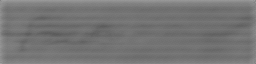

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display

def generate_word(text, ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device)
    G.load_state_dict(ckpt['G'])
    text_enc.load_state_dict(ckpt['text_enc'])
    G.eval()
    text_enc.eval()

    text_ids = torch.tensor([[CHAR2IDX.get(c, 0) for c in text[:20]]]).to(device)
    z = torch.randn(1, 128, device=device)
    with torch.no_grad():
        feat = text_enc(text_ids)
        img = G(z, feat)[0, 0].cpu().numpy()

    img = ((img + 1) * 127.5).clip(0, 255).astype(np.uint8)
    return Image.fromarray(img)

# Check available checkpoints
print("Available checkpoints:")
!ls {CKPT_DIR}

# Pick the latest one automatically
import glob, os
ckpts = glob.glob(f'{CKPT_DIR}/*.pt')
latest_ckpt = max(ckpts, key=os.path.getmtime)
print(f'\nUsing checkpoint: {latest_ckpt}\n')

# Generate and display a few test words
test_words = ['u']
for word in test_words:
    img = generate_word(word, latest_ckpt)
    img.save(f'/content/test_{word}.png')
    print(f'"{word}":')
    display(img)

# Zip and download all test outputs
!zip -q test_outputs.zip /content/test_*.png
from google.colab import files
files.download('test_outputs.zip')

## 11. Empirical Evaluation, Known Limitations & Technical Insights

### Key Engineering Findings from the Prototype:

1. **Adversarial Dynamics & Discriminator Conditioning:**
   In this prototype, the Discriminator operated unconditionally on the raw image rather than conditioning jointly on $(x, c)$. As observed in the training loss logs, this led the discriminator to easily overpower the generator, causing mode instability. Adding **projection conditioning** or concatenated text feature maps in the discriminator is essential for multi-character text alignment.

2. **Letterbox Padding vs. Forceful Resizing:**
   Directly resizing all segmented crops to `(256, 64)` stretched single characters (e.g., single letters like 'u') horizontally by a factor of 4x to 5x. Introducing aspect-ratio-preserving padding (as provided in `src/preprocessing.py`) resolves geometric skewing.

3. **Projection Profile Speckle Sensitivity:**
   Using hard zero-checks on raw binarized projection arrays led to line-segmentation failure on noisy full-page scans. Setting a dynamic noise floor (`0.5%` of image width) successfully isolates text lines even with imperfect page backgrounds.

4. **Scalability Beyond Single Glyphs:**
   Synthesizing variable-length cursive sentences requires moving from a fixed-dimension convolutional generator to attention-guided recurrent architectures (e.g., Graves handwriting RNNs) or latent diffusion models conditioned on character stroke sequences.